# E-commerce Customer Retention and Churn-Risk Analysis

Objective:
Analyze customer purchasing behavior to identify repeat customers,
inactive customers, and potential churn-risk segments.

In [5]:
import pandas as pd
import numpy as np
import os

 # Customers inspection

In [31]:
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
print("Loaded successfully")

Loaded successfully


In [32]:
customers.head(5)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [45]:
customers.shape

(99441, 5)

In [44]:
customers.columns
customers.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [40]:
# Check duplicate rows
customers.duplicated().sum()

np.int64(0)

 # Orders inspection

In [46]:
# Load orders data
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

# Check number of rows and columns
orders.shape

(99441, 8)

In [47]:
# Check missing values
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [48]:
# Check duplicate order IDs
orders["order_id"].duplicated().sum()

np.int64(0)

In [49]:
# Check order status values
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [53]:
# Load order items data
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

# Check number of rows and columns
order_items.shape

(112650, 7)

In [54]:
# Check missing values
order_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [55]:
# Check duplicate rows
order_items.duplicated().sum()

np.int64(0)

In [56]:
# Check duplicate order-item combinations
order_items.duplicated(subset=["order_id", "order_item_id"]).sum()

np.int64(0)

In [57]:
# Check basic price statistics
order_items["price"].describe()

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

 # Payments inspection

In [58]:
# Load payments data
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")

# Check number of rows and columns
payments.shape

(103886, 5)

In [59]:
# Check missing values
payments.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [60]:
# Check duplicate rows
payments.duplicated().sum()

np.int64(0)

In [61]:
# Check payment types
payments["payment_type"].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [62]:
# Check payment value statistics
payments["payment_value"].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

# Reviews inspection

In [63]:
# Load reviews data
reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")

# Check number of rows and columns
reviews.shape

(99224, 7)

In [64]:
# Check missing values
reviews.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [65]:
# Check duplicate rows
reviews.duplicated().sum()

np.int64(0)

In [66]:
# Check duplicate review IDs
reviews["review_id"].duplicated().sum()

np.int64(814)

In [67]:
# Check review score distribution
reviews["review_score"].value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

# Products inspection

In [68]:
# Load products data
products = pd.read_csv("../data/raw/olist_products_dataset.csv")

# Check number of rows and columns
products.shape

(32951, 9)

In [69]:
# Check missing values
products.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [70]:
# Check duplicate product IDs
products["product_id"].duplicated().sum()

np.int64(0)

In [71]:
# Check missing product categories
products["product_category_name"].isnull().sum()

np.int64(610)

# Category translation inspection

In [8]:
# Load category translation data
category_translation = pd.read_csv("../data/raw/product_category_name_translation.csv")

# Check number of rows and columns
category_translation.shape

(71, 2)

In [9]:
# Check missing values
category_translation.isnull().sum()

product_category_name            0
product_category_name_english    0
dtype: int64

In [10]:
# Check duplicate category names
category_translation["product_category_name"].duplicated().sum()

np.int64(0)

# Cleaning
### Convert and Fix the Date Data Type

In [12]:
# Load all required datasets
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")
reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")
products = pd.read_csv("../data/raw/olist_products_dataset.csv")
category_translation = pd.read_csv("../data/raw/product_category_name_translation.csv")

In [14]:
orders.dtypes

order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

In [15]:
# Convert order date columns to datetime
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
orders["order_approved_at"] = pd.to_datetime(orders["order_approved_at"])
orders["order_delivered_carrier_date"] = pd.to_datetime(orders["order_delivered_carrier_date"])
orders["order_delivered_customer_date"] = pd.to_datetime(orders["order_delivered_customer_date"])
orders["order_estimated_delivery_date"] = pd.to_datetime(orders["order_estimated_delivery_date"])

# Check date conversion
orders.dtypes

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

### Clean products and categories

In [26]:
# Fill missing product categories
products["product_category_name"] = products["product_category_name"].fillna("unknown")

In [29]:
# Translate product categories to English
products = products.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

In [33]:
# Fill untranslated categories
products["product_category_name_english"] = products["product_category_name_english"].fillna("unknown")

In [35]:
# Check result
products[["product_id", "product_category_name", "product_category_name_english"]].head()

,product_id,product_category_name,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares


In [36]:
# Check how many products still have unknown English category
products["product_category_name_english"].value_counts().head(10)

product_category_name_english
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
watches_gifts            1329
telephony                1134
Name: count, dtype: int64

In [31]:
products.head(10)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,housewares
5,41d3672d4792049fa1779bb35283ed13,instrumentos_musicais,60.0,745.0,1.0,200.0,38.0,5.0,11.0,musical_instruments
6,732bd381ad09e530fe0a5f457d81becb,cool_stuff,56.0,1272.0,4.0,18350.0,70.0,24.0,44.0,cool_stuff
7,2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,56.0,184.0,2.0,900.0,40.0,8.0,40.0,furniture_decor
8,37cc742be07708b53a98702e77a21a02,eletrodomesticos,57.0,163.0,1.0,400.0,27.0,13.0,17.0,home_appliances
9,8c92109888e8cdf9d66dc7e463025574,brinquedos,36.0,1156.0,1.0,600.0,17.0,10.0,12.0,toys


In [30]:
products["product_category_name"].head(15)

0               perfumaria
1                    artes
2            esporte_lazer
3                    bebes
4    utilidades_domesticas
Name: product_category_name, dtype: object

 ### Create delivered-orders dataset

In [37]:
# Keep only delivered orders for RFM and retention analysis
delivered_orders = orders[orders["order_status"] == "delivered"].copy()

In [38]:
# Check number of delivered orders
delivered_orders.shape

(96478, 8)

In [39]:
# Check date range of delivered orders
delivered_orders["order_purchase_timestamp"].min(), delivered_orders["order_purchase_timestamp"].max()

(Timestamp('2016-09-15 12:16:38'), Timestamp('2018-08-29 15:00:37'))

 ### Join customers with delivered orders

In [40]:
# Join delivered orders with customer information
delivered_orders_customers = delivered_orders.merge(
    customers,
    on="customer_id",
    how="left"
)

# Check the result
delivered_orders_customers.shape

(96478, 12)

In [41]:
# Check first few rows
delivered_orders_customers.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


 ### Join order items

In [42]:
# Join delivered orders with order items
delivered_orders_items = delivered_orders_customers.merge(
    order_items,
    on="order_id",
    how="left"
)

# Check the result
delivered_orders_items.shape

(110197, 18)

In [43]:
# Check first few rows
delivered_orders_items.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


 ### Join payments

In [44]:
# Join delivered orders with payment information
delivered_orders_payments = delivered_orders_items.merge(
    payments,
    on="order_id",
    how="left"
)

# Check the result
delivered_orders_payments.shape

(115038, 22)

In [45]:
# Check first few rows
delivered_orders_payments.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,1.0,credit_card,1.0,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,3.0,voucher,1.0,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,2.0,voucher,1.0,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,1.0,boleto,1.0,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,1.0,credit_card,3.0,179.12


### Fix: Aggregate payments by order

In [46]:
# Combine multiple payment records for each order
payments_order_level = payments.groupby("order_id").agg(
    total_payment_value=("payment_value", "sum"),
    payment_type_count=("payment_type", "count"),
    main_payment_type=("payment_type", "first")
).reset_index()

# Check result
payments_order_level.head()

,order_id,total_payment_value,payment_type_count,main_payment_type
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,1,credit_card
1,00018f77f2f0320c557190d7a144bdd3,259.83,1,credit_card
2,000229ec398224ef6ca0657da4fc703e,216.87,1,credit_card
3,00024acbcdf0a6daa1e931b038114c75,25.78,1,credit_card
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,1,credit_card


In [47]:
payments_order_level.head(20)

,order_id,total_payment_value,payment_type_count,main_payment_type
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,1,credit_card
1,00018f77f2f0320c557190d7a144bdd3,259.83,1,credit_card
2,000229ec398224ef6ca0657da4fc703e,216.87,1,credit_card
3,00024acbcdf0a6daa1e931b038114c75,25.78,1,credit_card
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,1,credit_card
5,00048cc3ae777c65dbb7d2a0634bc1ea,34.59,1,boleto
6,00054e8431b9d7675808bcb819fb4a32,31.75,1,credit_card
7,000576fe39319847cbb9d288c5617fa6,880.75,1,credit_card
8,0005a1a1728c9d785b8e2b08b904576c,157.60,1,credit_card
9,0005f50442cb953dcd1d21e1fb923495,65.39,1,credit_card


In [48]:
# Join delivered orders with combined payment information
delivered_orders_payments = delivered_orders_items.merge(
    payments_order_level,
    on="order_id",
    how="left"
)

# Check the result
delivered_orders_payments.shape

(110197, 21)

### Add review scores

In [50]:
# Combine review information for each order
reviews_order_level = reviews.groupby("order_id").agg(
    review_score=("review_score", "mean"),
    review_count=("review_id", "count")
).reset_index()

In [51]:
# Join reviews to the main table
delivered_orders_reviews = delivered_orders_payments.merge(
    reviews_order_level,
    on="order_id",
    how="left"
)

In [52]:
# Check result
delivered_orders_reviews.shape

(110197, 23)

In [53]:
delivered_orders_reviews[["order_id", "review_score", "review_count"]].head()

,order_id,review_score,review_count
0,e481f51cbdc54678b7cc49136f2d6af7,4.0,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,4.0,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,5.0,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,5.0,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,5.0,1.0


 ### Create customer-level table

In [54]:
# Create one row per customer with summary metrics
customer_summary = delivered_orders_reviews.groupby("customer_unique_id").agg(
    total_orders=("order_id", "nunique"),
    total_items=("order_item_id", "count"),
    total_spent=("price", "sum"),
    total_freight=("freight_value", "sum"),
    total_payment=("total_payment_value", "sum"),
    average_review_score=("review_score", "mean"),
    first_order_date=("order_purchase_timestamp", "min"),
    last_order_date=("order_purchase_timestamp", "max")
).reset_index()

# Check result
customer_summary.shape

(93358, 9)

In [55]:
# Count customers by number of orders
customer_summary["total_orders"].value_counts().sort_index()

total_orders
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

### Create a repeat-customer flag

In [56]:
# Flag customers with more than one order
customer_summary["is_repeat_customer"] = (
    customer_summary["total_orders"] > 1
).astype(int)

# Check how many repeat customers there are
customer_summary["is_repeat_customer"].value_counts()

is_repeat_customer
0    90557
1     2801
Name: count, dtype: int64

### Understanding when customers stopped ordering

In [57]:
# Find the most recent order date in the dataset
latest_date = customer_summary["last_order_date"].max()

In [58]:
# Calculate days since each customer's last order
customer_summary["days_since_last_order"] = (
    latest_date - customer_summary["last_order_date"]
).dt.days

In [59]:
# Check a few rows
customer_summary[[
    "customer_unique_id",
    "total_orders",
    "last_order_date",
    "days_since_last_order"
]].head()

,customer_unique_id,total_orders,last_order_date,days_since_last_order
0,0000366f3b9a7992bf8c76cfdf3221e2,1,2018-05-10 10:56:27,111
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,2018-05-07 11:11:27,114
2,0000f46a3911fa3c0805444483337064,1,2017-03-10 21:05:03,536
3,0000f6ccb0745a6a4b88665a16c9f078,1,2017-10-12 20:29:41,320
4,0004aac84e0df4da2b147fca70cf8255,1,2017-11-14 19:45:42,287


In [60]:
# Find the most recent order date in the dataset
latest_date = customer_summary["last_order_date"].max()

# Calculate days since each customer's last order
customer_summary["days_since_last_order"] = (
    latest_date - customer_summary["last_order_date"]
).dt.days

# Check a few rows
customer_summary[[
    "customer_unique_id",
    "total_orders",
    "last_order_date",
    "days_since_last_order"
]].head()

,customer_unique_id,total_orders,last_order_date,days_since_last_order
0,0000366f3b9a7992bf8c76cfdf3221e2,1,2018-05-10 10:56:27,111
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,2018-05-07 11:11:27,114
2,0000f46a3911fa3c0805444483337064,1,2017-03-10 21:05:03,536
3,0000f6ccb0745a6a4b88665a16c9f078,1,2017-10-12 20:29:41,320
4,0004aac84e0df4da2b147fca70cf8255,1,2017-11-14 19:45:42,287


### Flag Inactive Customers

In [61]:
# Flag customers with no order in the last 180 days
customer_summary["is_inactive"] = (
    customer_summary["days_since_last_order"] > 180
).astype(int)

# Check how many customers are inactive
customer_summary["is_inactive"].value_counts()

is_inactive
1    55006
0    38352
Name: count, dtype: int64

### Compare one-time vs repeat customers

In [62]:
# Compare average behavior of one-time and repeat customers
customer_summary.groupby("is_repeat_customer").agg(
    customers=("customer_unique_id", "count"),
    average_orders=("total_orders", "mean"),
    average_spent=("total_spent", "mean"),
    average_review_score=("average_review_score", "mean"),
    average_days_since_last_order=("days_since_last_order", "mean")
)

,customers,average_orders,average_spent,average_review_score,average_days_since_last_order
is_repeat_customer,,,,,
0,90557,1.000000,137.958295,4.152029,237.487616
1,2801,2.113888,260.053106,4.195494,219.294538


###  Create customer segments

In [63]:
# Create simple customer segments
def create_segment(row):
    if row["is_repeat_customer"] == 1 and row["is_inactive"] == 0:
        return "Active repeat customer"
    elif row["is_repeat_customer"] == 1 and row["is_inactive"] == 1:
        return "Inactive repeat customer"
    elif row["is_repeat_customer"] == 0 and row["is_inactive"] == 0:
        return "Active one-time customer"
    else:
        return "Inactive one-time customer"

customer_summary["customer_segment"] = customer_summary.apply(create_segment, axis=1)

# Check segment sizes
customer_summary["customer_segment"].value_counts()

customer_segment
Inactive one-time customer    53446
Active one-time customer      37111
Inactive repeat customer       1560
Active repeat customer         1241
Name: count, dtype: int64

# Visualization Results

### 1. customer segment

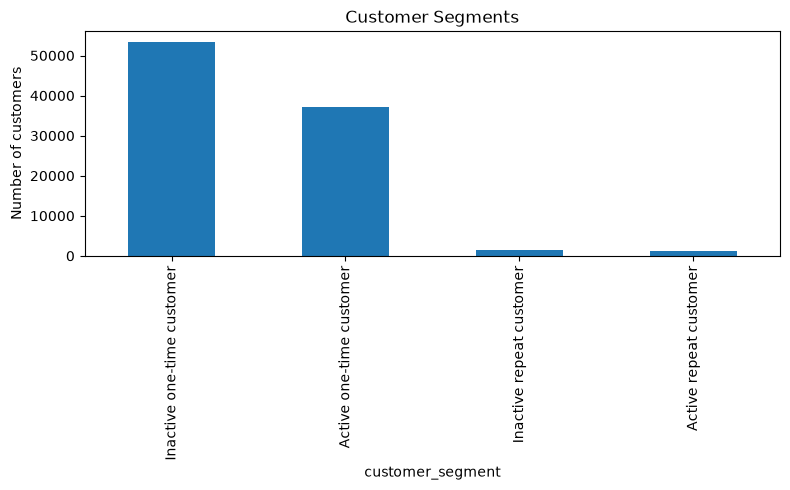

In [65]:
import matplotlib.pyplot as plt

# Chart 1: customer segments
customer_summary["customer_segment"].value_counts().plot(
    kind="bar",
    title="Customer Segments",
    figsize=(8, 5)
)
plt.ylabel("Number of customers")
plt.tight_layout()
plt.savefig("customer_segments.png")
plt.show()

### 2. repeat vs one-time customers

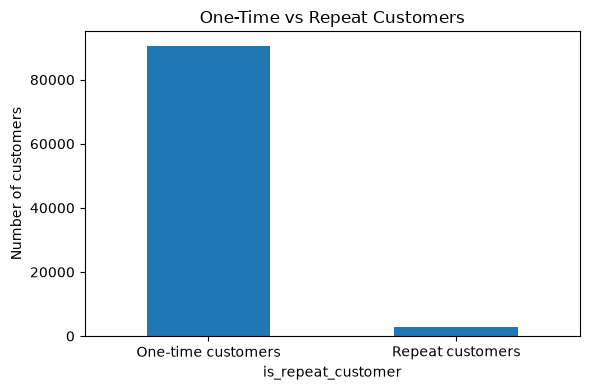

In [66]:
import matplotlib.pyplot as plt

# Chart 2: repeat vs one-time customers
customer_summary["is_repeat_customer"].value_counts().plot(
    kind="bar",
    title="One-Time vs Repeat Customers",
    figsize=(6, 4)
)

plt.xticks([0, 1], ["One-time customers", "Repeat customers"], rotation=0)
plt.ylabel("Number of customers")
plt.tight_layout()
plt.savefig("repeat_customers.png")
plt.show()

### 3. customer spending

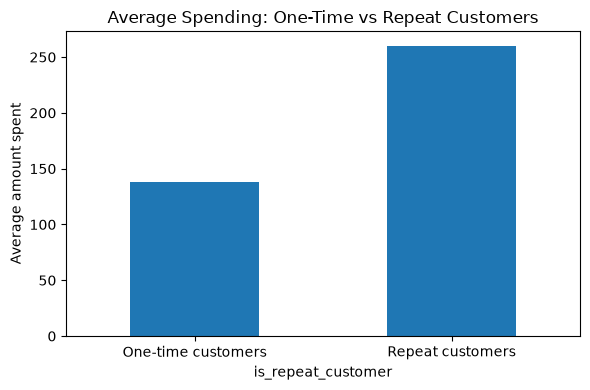

In [67]:
import matplotlib.pyplot as plt

# Chart 3: average spending by customer type
customer_summary.groupby("is_repeat_customer")["total_spent"].mean().plot(
    kind="bar",
    title="Average Spending: One-Time vs Repeat Customers",
    figsize=(6, 4)
)

plt.xticks([0, 1], ["One-time customers", "Repeat customers"], rotation=0)
plt.ylabel("Average amount spent")
plt.tight_layout()
plt.savefig("spending_comparison.png")
plt.show()

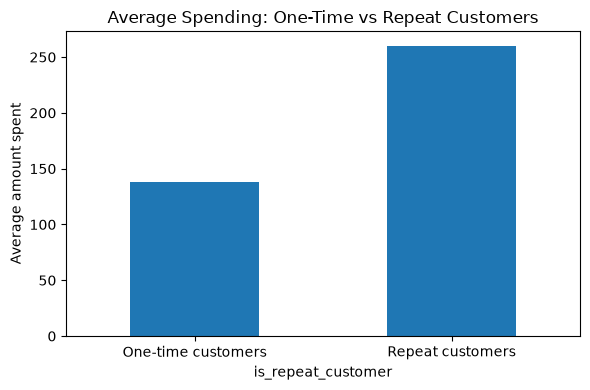

In [68]:
import matplotlib.pyplot as plt

# Chart 3: average spending by customer type
customer_summary.groupby("is_repeat_customer")["total_spent"].mean().plot(
    kind="bar",
    title="Average Spending: One-Time vs Repeat Customers",
    figsize=(6, 4)
)

plt.xticks([0, 1], ["One-time customers", "Repeat customers"], rotation=0)
plt.ylabel("Average amount spent")
plt.tight_layout()
plt.savefig("spending_comparison.png")
plt.show()

In [69]:
# Keep one row per order using the order-level payment table
orders_payment = delivered_orders_reviews[
    ["order_id", "customer_unique_id"]
].drop_duplicates(subset="order_id")

# Attach the correct total payment for each order
orders_payment = orders_payment.merge(
    payments_order_level[["order_id", "total_payment_value"]],
    on="order_id",
    how="left"
)

# Recalculate total payment per customer
correct_payment = orders_payment.groupby("customer_unique_id")["total_payment_value"].sum()

# Replace the incorrect column
customer_summary["total_payment"] = customer_summary["customer_unique_id"].map(correct_payment)

# Check the corrected values
customer_summary[["customer_unique_id", "total_orders", "total_spent", "total_payment"]].head()

,customer_unique_id,total_orders,total_spent,total_payment
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,27.19
2,0000f46a3911fa3c0805444483337064,1,69.00,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,43.62
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,196.89


### Final: Export the cleaned output file(CSV)

In [71]:
customer_summary.to_csv("customer_summary.csv", index=False)

## Key Findings

- Around 97% of customers placed only one order.
- About 59% of customers were inactive for more than 180 days.
- The largest segment was inactive one-time customers.
- Repeat customers spent more than one-time customers.
- Review scores were similar across customer types.

Note:
The 180-day inactivity rule is an assumption.
Inactive customers are not confirmed churned customers.